# IND320 Project work, part 3: Weather data, outliers and decomposition

**Ismail Nabi** · NMBU · IND320

## Links
- GitHub repository: https://github.com/IsmailNabi/IND320-prosjekt
- Streamlit app: https://ismail.streamlit.app
- Screencast: *add link here*

## Contents
0. Setup
1. Regions and 1000 random locations per region
2. Weather data from open-meteo (ERA5)
3. Outliers (precipitation) and anomalies (temperature)
4. STL decomposition of the filling degree
5. Spectrogram of the filling degree
6. Log and AI usage

All analysis functions live in `modules/` so that the notebook and the Streamlit app
use exactly the same code. Their source is printed in the notebook for documentation.

## 0. Setup

In [24]:
# Imports and paths. The notebook lives in notebooks/, the shared code in ../modules
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent                      # project root
sys.path.insert(0, str(ROOT))

from modules import api, analysis, db, decomposition, outliers, regions, weather
from modules.config import get_secrets
from modules.helpers import prepare_reservoir_df

SECRETS = get_secrets()                        # passwords from No_sync/secrets.toml (not on GitHub)

## 1. Regions and random locations

### 1.1 Shapefiles from atlas.nve.no
I downloaded two shapefiles from [atlas.nve.no](https://atlas.nve.no) (saved in `data/shapefiles/`):

- **Budområder**: the price areas NO1-NO5, which match the `EL` areas in Magasinstatistikk.
- **NVE_Region**: five regions (RV, RM, RN, RØ, RS), used for the four `VASS` areas.

The task says *East is split into RS+RØ, and North is split into RM+RN*. Together with the area descriptions from the API this gives:

| VASS | Area | NVE regions |
|---|---|---|
| 1 | South-East Norway | RØ + RS |
| 2 | West Norway | RV |
| 3 | Mid Norway | RM |
| 4 | North Norway | RN |

`NO` (all of Norway) is all regions together.

In [25]:
# Area names and descriptions from the NVE API
areas = api.fetch_areas()
display(areas)

,area_type,area_number,name
0,NO,0,Norge
1,EL,1,NO 1
2,EL,2,NO 2
3,EL,3,NO 3
4,EL,4,NO 4
5,EL,5,NO 5
6,VASS,1,VASS1
7,VASS,2,VASS2
8,VASS,3,VASS3
9,VASS,4,VASS4


In [26]:
# One polygon (map shape) per area: "EL-3" = NO3, "VASS-1", "NO-0" = Norway, ...
polygons = regions.load_region_polygons()
display((polygons.area / 1e6).round(0).rename("area (km²)").to_frame())

,area (km²)
region,
NO-0,470107.0
EL-1,60529.0
EL-2,68760.0
EL-3,104220.0
EL-4,203250.0
EL-5,33349.0
VASS-1,138366.0
VASS-2,75414.0
VASS-3,88747.0


### 1.2 1000 random locations per region
For each area I draw random points and keep those that fall inside the area, until there are 1000.
This is done in metres so that every km² has the same chance. The points are then converted to
longitude/latitude for the weather API. A fixed seed gives the same points every time.

In [27]:
# Draw 1000 points in each of the 10 areas and save them as a CSV file
points = regions.sample_region_points(polygons, n=1000, seed=320)
points.to_csv(regions.POINTS_FILE, index=False)
print(points.shape)
display(points.groupby("region").size().rename("points").to_frame())

(10000, 4)


,points
region,
EL-1,1000
EL-2,1000
EL-3,1000
EL-4,1000
EL-5,1000
NO-0,1000
VASS-1,1000
VASS-2,1000
VASS-3,1000


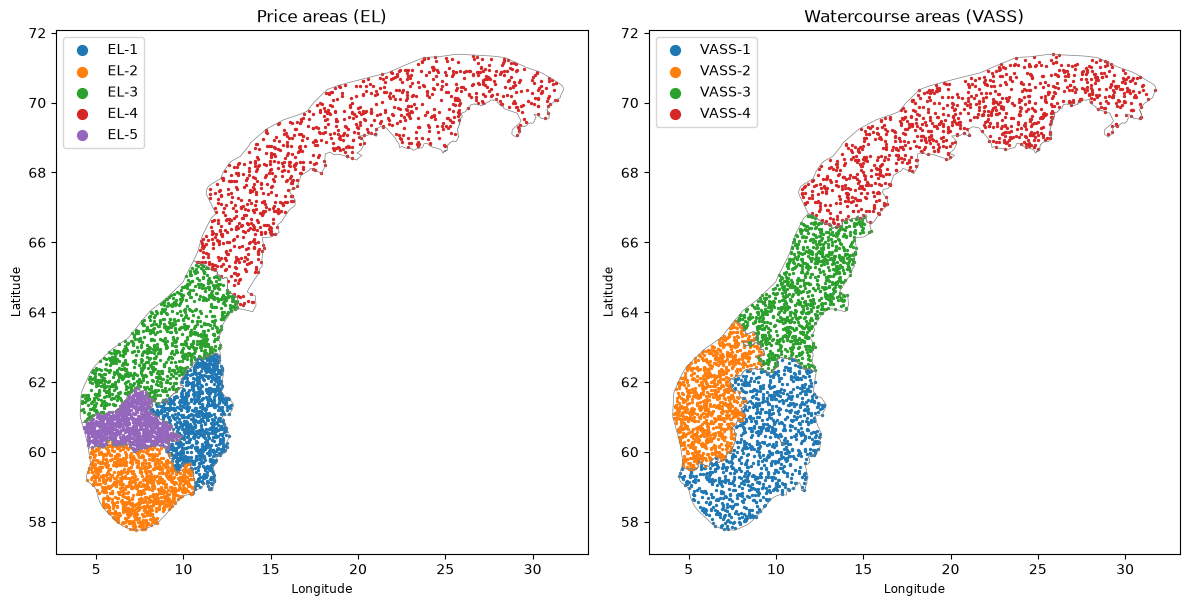

In [28]:
# Map of the points: price areas (EL) and watercourse areas (VASS)
fig, axes = plt.subplots(1, 2, figsize=(12, 7))
for ax, prefix, title in zip(axes, ["EL", "VASS"], ["Price areas (EL)", "Watercourse areas (VASS)"]):
    polygons.to_crs(4326).loc[[r for r in polygons.index if r.startswith(prefix)]].boundary.plot(ax=ax, color="grey", lw=0.5)
    for region, grp in points[points["region"].str.startswith(prefix)].groupby("region"):
        ax.scatter(grp["lon"], grp["lat"], s=2, label=region)
    ax.set_title(title); ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
    ax.set_aspect(2)                            # roughly correct proportions this far north
    ax.legend(markerscale=5)
plt.tight_layout()
plt.show()

In [29]:
# Save the points in MongoDB so the Streamlit app can read them
m = SECRETS["mongo"]
client = db.get_client(db.build_uri(m["user"], m["password"], m["host"]))
collection = client[m["database"]]["sample_points"]
collection.delete_many({})                      # replace old content
collection.insert_many(points.to_dict("records"))
print("Points in MongoDB:", collection.count_documents({}))

Points in MongoDB: 10000


## 2. Weather data from open-meteo

I use the [Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api) with the
**ERA5** model (`models=era5`). The function `weather.download_weather(region, start, end, points)`:

1. takes an area (e.g. `"EL-3"` = NO3) and a time interval,
2. looks up the area's sampled points,
3. downloads hourly temperature, precipitation and some other variables (rain, snow, wind, clouds, ...),
4. returns one row per hour and location. `regional_mean` then averages over the locations.

It uses 10 of the 1000 points (in different ERA5 grid cells). All 1000 points would exceed the free
API limit, and ERA5's grid is about 25 km, so many points would give the same data anyway.

In [30]:
# Download NO3 (= EL-3) for 2024. The result is saved in No_sync/ so the API is only called once.
REGION, YEAR = "EL-3", 2024
CACHE = ROOT / "No_sync" / f"weather_{REGION}_{YEAR}.csv"
CACHE.parent.mkdir(exist_ok=True)

if CACHE.exists():
    weather_raw = pd.read_csv(CACHE, parse_dates=["time"])
else:
    weather_raw = weather.download_weather(REGION, f"{YEAR}-01-01", f"{YEAR}-12-31", points, n_locations=10)
    weather_raw.to_csv(CACHE, index=False)

print(weather_raw.shape, "| locations:", weather_raw["point_id"].nunique())
display(weather_raw.head())

(87840, 13) | locations: 10


,time,point_id,lon,lat,temperature_2m,precipitation,rain,snowfall,relative_humidity_2m,wind_speed_10m,wind_gusts_10m,cloud_cover,surface_pressure
0,2024-01-01 00:00:00,993,10.20346,64.75073,-2.4,0.0,0.0,0.0,76,52.6,76.3,87,1011.9
1,2024-01-01 01:00:00,993,10.20346,64.75073,-2.4,0.0,0.0,0.0,76,52.5,77.4,91,1011.6
2,2024-01-01 02:00:00,993,10.20346,64.75073,-2.4,0.0,0.0,0.0,76,53.2,79.2,98,1011.6
3,2024-01-01 03:00:00,993,10.20346,64.75073,-2.4,0.0,0.0,0.0,76,53.8,80.3,98,1011.6
4,2024-01-01 04:00:00,993,10.20346,64.75073,-2.3,0.0,0.0,0.0,75,54.5,81.4,100,1011.2


In [31]:
# Average over the 10 locations -> one value per hour for NO3
no3 = weather.regional_mean(weather_raw)
print(len(no3), "hours (2024 is a leap year: 8784)")
display(no3.describe().T.round(2))

8784 hours (2024 is a leap year: 8784)


,count,mean,std,min,25%,50%,75%,max
temperature_2m,8784.0,6.45,6.80,-11.74,1.85,6.12,11.84,23.83
precipitation,8784.0,0.20,0.28,0.00,0.01,0.10,0.28,2.29
rain,8784.0,0.18,0.26,0.00,0.01,0.08,0.25,2.07
snowfall,8784.0,0.01,0.04,0.00,0.00,0.00,0.01,0.71
relative_humidity_2m,8784.0,79.71,9.01,43.60,74.40,81.50,86.30,96.30
wind_speed_10m,8784.0,15.11,6.09,2.70,10.58,13.96,18.80,47.27
wind_gusts_10m,8784.0,32.61,13.61,8.32,22.47,29.92,39.68,106.62
cloud_cover,8784.0,77.18,22.51,1.00,64.90,84.10,96.00,100.00
surface_pressure,8784.0,975.64,12.24,926.78,968.27,976.34,984.35,1004.56


## 3. Outliers and anomalies

### 3.1 Precipitation: SPC outliers
1. A DCT high-pass filter removes the slow seasonal variation (everything slower than 30 days).
   What is left is called SATV and shows the short-term variation.
2. From SATV I calculate robust limits: median ± 3 robust standard deviations (1.4826 · MAD).
3. The limits are moved back on top of the seasonal curve, so they follow the original data.
   SATV itself is not plotted.
4. Hours outside the limits are outliers (red).

The cut-off (days) and the number of standard deviations are parameters.

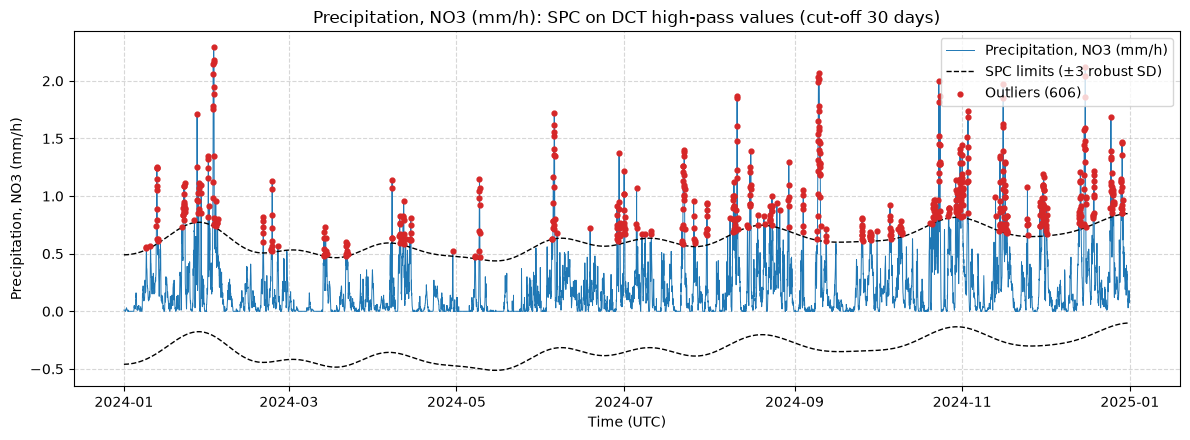

,value
observations,8784.0000
outliers,606.0000
outlier share (%),6.9000
high outliers,606.0000
low outliers,0.0000
DCT coefficients removed,25.0000
SATV median,-0.0609
SATV robust SD (1.4826·MAD),0.1583
largest outlier value,2.2900


,time,value,lower_limit,upper_limit,direction
58,2024-02-02 16:00:00,2.29,-0.214241,0.735698,high
60,2024-02-02 18:00:00,2.18,-0.215338,0.734601,high
59,2024-02-02 17:00:00,2.16,-0.214788,0.735151,high
54,2024-02-02 12:00:00,2.15,-0.212088,0.737852,high
555,2024-12-15 19:00:00,2.12,-0.223578,0.726362,high
315,2024-09-09 21:00:00,2.07,-0.336408,0.613531,high
55,2024-02-02 13:00:00,2.06,-0.212621,0.737318,high
554,2024-12-15 18:00:00,2.04,-0.223953,0.725987,high
311,2024-09-09 17:00:00,2.03,-0.335693,0.614246,high
314,2024-09-09 20:00:00,2.02,-0.336232,0.613708,high


In [32]:
# Test 1: default settings (cut-off 30 days, 3 standard deviations), hourly precipitation
fig, stats, prec_out = outliers.spc_outliers(no3["precipitation"], title="Precipitation, NO3 (mm/h)")
plt.show()
display(stats.to_frame("value"))
display(prec_out.sort_values("value", ascending=False).head(10))

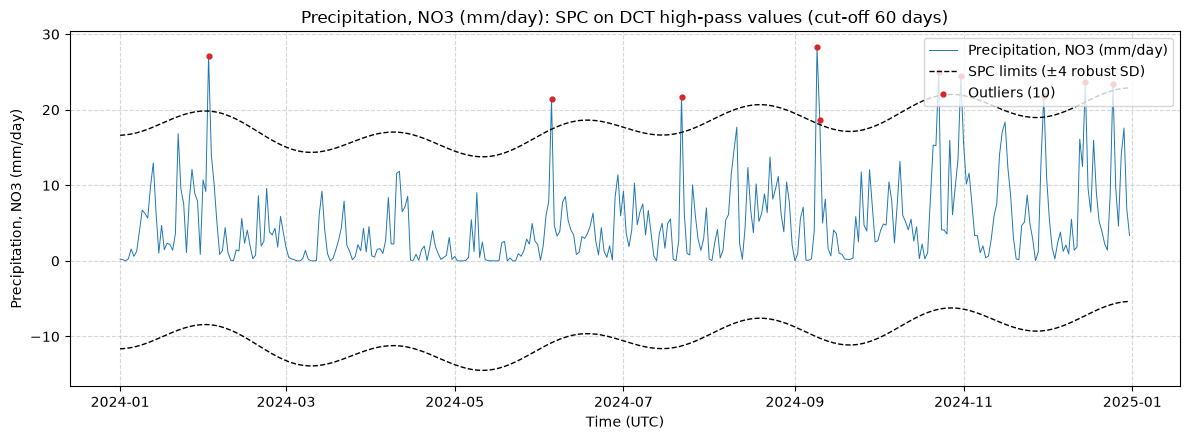

,value
observations,366.0000
outliers,10.0000
outlier share (%),2.7300
high outliers,10.0000
low outliers,0.0000
DCT coefficients removed,13.0000
SATV median,-0.9265
SATV robust SD (1.4826·MAD),3.5327
largest outlier value,28.2400


,time,value,lower_limit,upper_limit,direction
0,2024-02-02,27.16,-8.440475,19.821077,high
1,2024-06-05,21.36,-10.838269,17.423283,high
2,2024-07-22,21.75,-11.259372,17.002180,high
3,2024-09-09,28.24,-10.075775,18.185777,high
4,2024-09-10,18.63,-10.229253,18.032299,high
5,2024-10-23,25.02,-6.402926,21.858626,high
6,2024-10-31,24.41,-6.329134,21.932418,high
7,2024-11-30,21.80,-9.238577,19.022975,high
8,2024-12-15,23.62,-7.243880,21.017672,high
9,2024-12-25,23.40,-5.713306,22.548246,high


In [33]:
# Test 2: daily totals, cut-off 60 days and 4 standard deviations -> only the most extreme days
daily = no3["precipitation"].resample("D").sum()
fig, stats, daily_out = outliers.spc_outliers(daily, cutoff_days=60, n_std=4, title="Precipitation, NO3 (mm/day)")
plt.show()
display(stats.to_frame("value"))
display(daily_out)

**Comment.** Precipitation is never negative and most hours are dry, so the lower limit is below
zero and all outliers are heavy showers. Daily totals give fewer and more meaningful outliers.

### 3.2 Temperature: LOF anomalies
Local Outlier Factor compares each hour with its nearest neighbours in time and temperature.
An hour that is very different from the hours around it is marked as an anomaly. The proportion
of anomalies is a parameter (default 1 %).

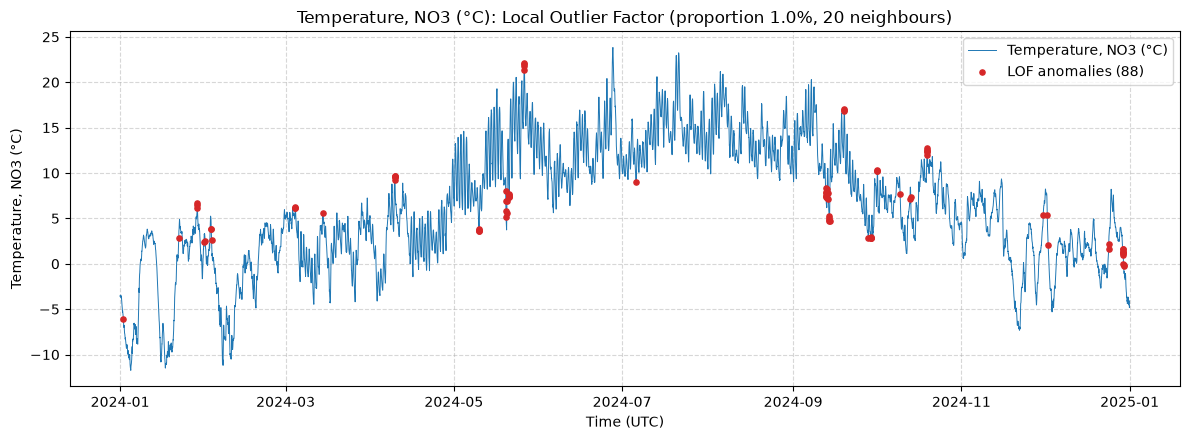

,value
observations,8784
anomalies,88
anomaly share (%),1.0
"mean value, all hours",6.45
"mean value, anomalies",6.79
highest LOF score,3.1
month with most anomalies,2024-09


,time,value,lof_score
0,2024-10-19 14:00:00,12.71,3.101873
1,2024-10-19 13:00:00,12.57,2.808069
2,2024-10-19 12:00:00,12.45,2.566705
3,2024-05-20 06:00:00,6.97,2.398382
4,2024-10-19 15:00:00,12.34,2.359166
5,2024-05-19 20:00:00,6.96,2.337051
6,2024-01-28 23:00:00,6.71,2.248504
7,2024-05-21 02:00:00,7.31,2.120326
8,2024-05-21 01:00:00,7.32,2.116301
9,2024-12-29 19:00:00,-0.11,2.113618


In [34]:
# Test 1: default settings (1 % anomalies, 20 neighbours)
fig, stats, temp_out = outliers.lof_anomalies(no3["temperature_2m"], title="Temperature, NO3 (°C)")
plt.show()
display(stats.to_frame("value"))
display(temp_out.head(10))

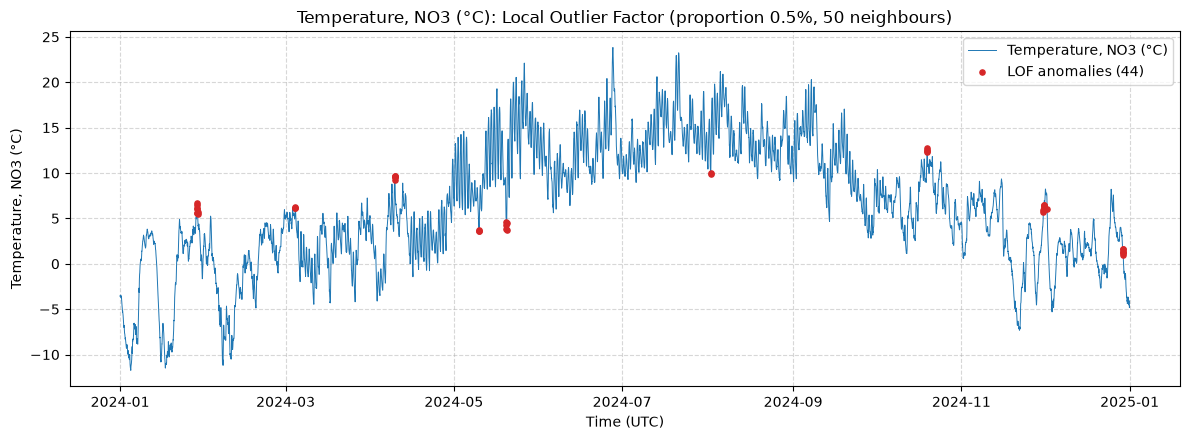

,value
observations,8784
anomalies,44
anomaly share (%),0.5
"mean value, all hours",6.45
"mean value, anomalies",6.21
highest LOF score,2.58
month with most anomalies,2024-01


In [35]:
# Test 2: 0.5 % anomalies and 50 neighbours -> only the most unusual hours
fig, stats, _ = outliers.lof_anomalies(no3["temperature_2m"], contamination=0.005, n_neighbors=50,
                                       title="Temperature, NO3 (°C)")
plt.show()
display(stats.to_frame("value"))

## 4. STL decomposition of the filling degree
STL splits the weekly filling degree of the reservoirs into **trend** (slow change over years),
**seasonal** (the yearly pattern, 52 weeks) and **residual** (what is left).
Parameters: seasonal smoother (default 13 weeks), trend smoother (default 105 weeks ≈ 2 years)
and robust (default False). I use NO3, the same area as the weather data.

In [36]:
# Reservoir data from the NVE API, filling degree for NO3 from 2010
reservoirs = analysis.add_area_names(prepare_reservoir_df(api.fetch_reservoirs_raw()), areas)
fill_no3 = decomposition.filling_series(reservoirs, "EL", 3, first_year=2010)
print(len(fill_no3), "weeks |", fill_no3.index.min().date(), "->", fill_no3.index.max().date())

879 weeks | 2010-01-03 -> 2026-11-01


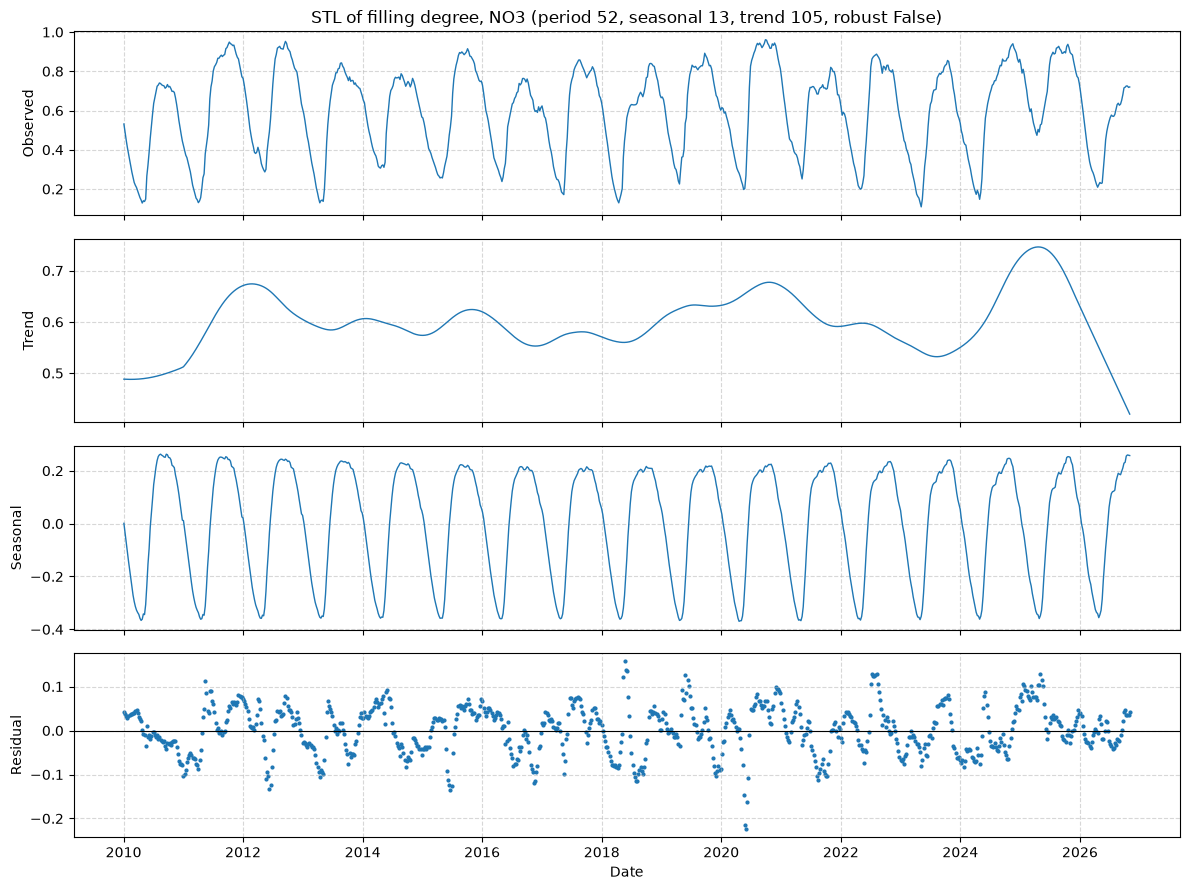

In [37]:
# Test 1: default settings
fig = decomposition.stl_plot(fill_no3, title="filling degree, NO3")
plt.show()

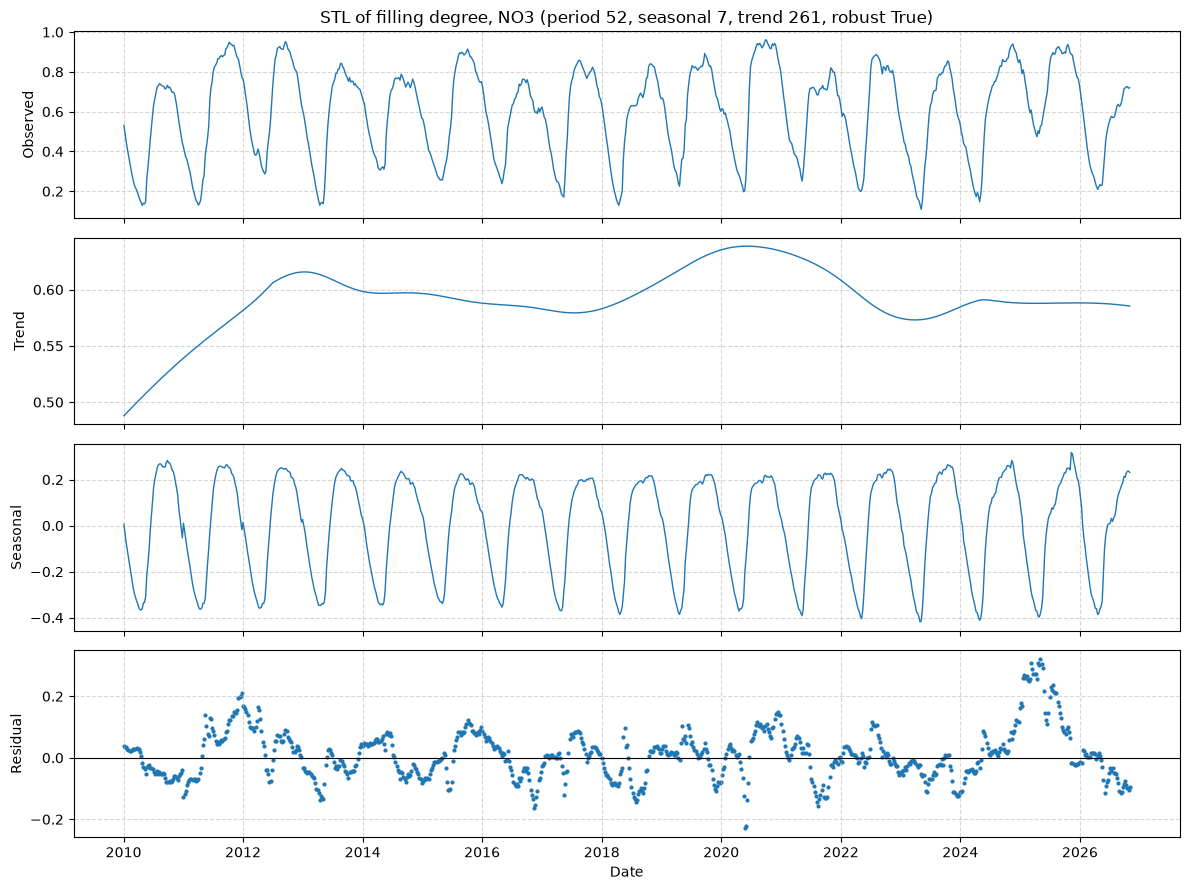

In [38]:
# Test 2: robust fit, shorter seasonal smoother and longer trend smoother
fig = decomposition.stl_plot(fill_no3, seasonal=7, trend=261, robust=True, title="filling degree, NO3")
plt.show()

**Comment.** The seasonal part shows the yearly cycle: the reservoirs are emptied during winter,
are lowest in spring and are filled by snow melt in early summer. The trend shows wet and dry years.

## 5. Spectrogram of the filling degree
A spectrogram shows which frequencies are present in the data over time. Parameters: window length
(default 104 weeks = 2 years) and overlap (default 78 weeks). Frequency is in cycles per year.

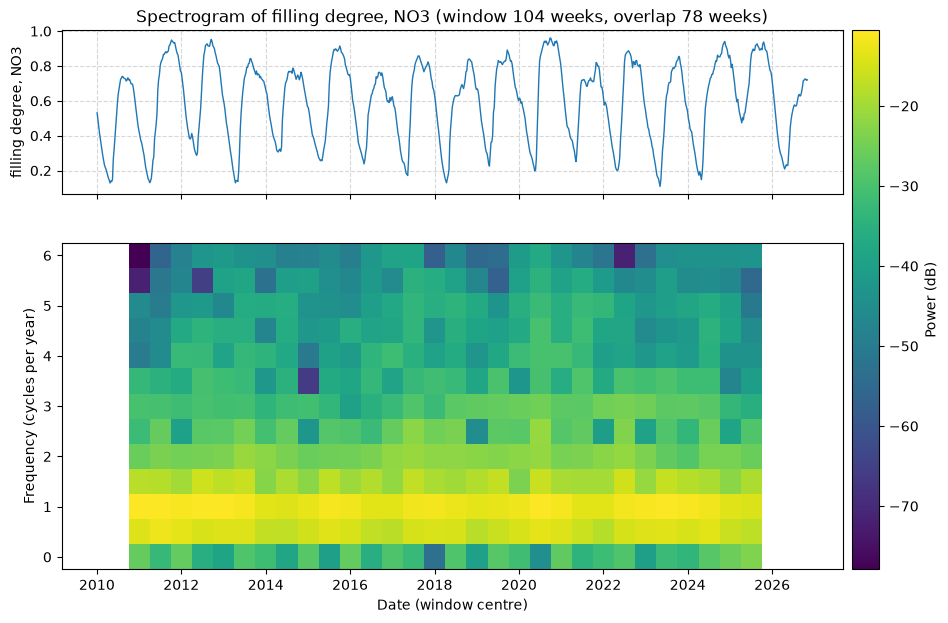

In [39]:
# Test 1: default settings
fig = decomposition.spectrogram_plot(fill_no3, title="filling degree, NO3")
plt.show()

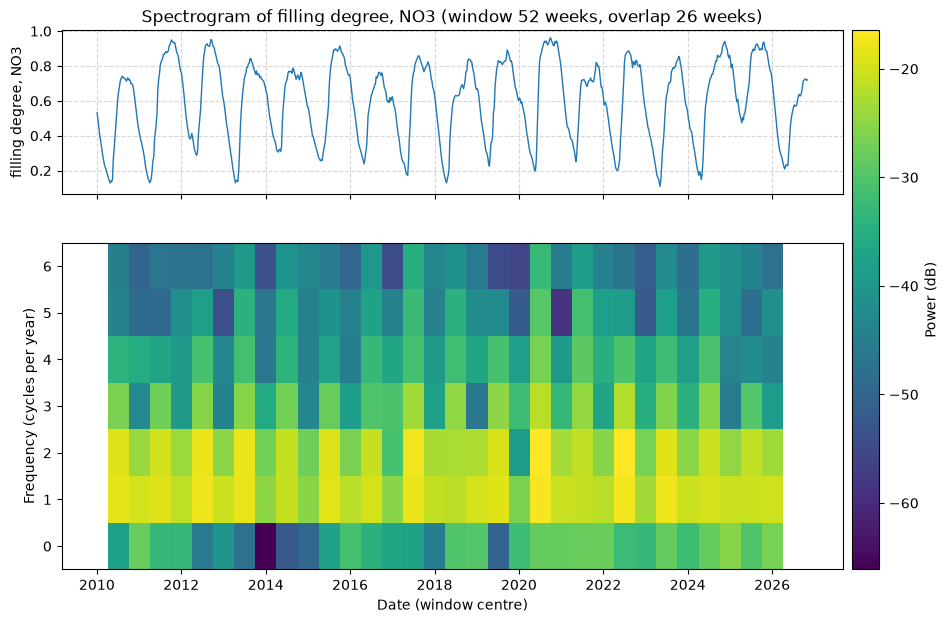

In [40]:
# Test 2: one-year window with half overlap -> sharper in time, less sharp in frequency
fig = decomposition.spectrogram_plot(fill_no3, window_length=52, window_overlap=26, title="filling degree, NO3")
plt.show()

**Comment.** The bright band at **1 cycle per year** is the yearly fill-and-empty cycle. The weaker
bands at 2-3 cycles per year come from the yearly curve not being a perfect wave.

## 6. Log and AI usage

### Log
*Draft: adjust to your own experience before submitting.*

Part 3 connected weather data to the reservoir data and added time-series analysis. As before I
worked on a separate branch so peer review 2 could be finished on main.

The first task was geographical. I downloaded two shapefiles from atlas.nve.no: the price areas
(Budområder, NO1-NO5) and NVE's regions (RV, RM, RN, RØ, RS). The price areas match the EL areas
directly, but the four VASS areas had to be matched to five regions. The hint in the task, together
with the area descriptions from the HentOmråder endpoint, gave VASS1 = RØ+RS, VASS2 = RV, VASS3 = RM
and VASS4 = RN, and the whole country is the union. I sampled 1000 random points in each region by
rejection sampling in metres (EPSG:25833) and stored them as a CSV file and in MongoDB.

For open-meteo I used the Historical Weather API with the ERA5 model. My download function takes a
region and a time interval, looks up the region's coordinates and downloads hourly temperature,
precipitation and seven more variables. Downloading 1000 points for a year would use far more than
the free daily quota, and ERA5 has a 25 km grid, so the function picks a few points in different grid
cells and averages them. I used UTC to avoid duplicated hours at daylight-saving changes.

The SPC task took the most thinking. The precipitation is high-pass filtered with the DCT, and the
robust limits (median ± 3 · 1.4826 · MAD) are calculated on these values but added back to the
low-pass part, so the limits follow the seasonal curve in the original plot. Precipitation is skewed
with many dry hours, so almost all outliers are heavy showers. For temperature I used LOF on scaled
time and temperature, as in the lecture, so it finds hours that differ from their surroundings. STL and
the spectrogram used the weekly filling degree with a period of 52; the spectrogram clearly shows
that the yearly cycle dominates.

In Streamlit I made the area a global setting in the sidebar, shared by all pages, while
method parameters stay local on each page. The weather download is hidden: it starts automatically
for the selected area, is cached for a day, and a short message with a map confirms what was
downloaded. One new page has tabs for STL and spectrogram, the other for SPC and LOF, and the pages
are grouped by data source (reservoirs, weather, power flows, documentation).

Part 3 connected weather data to the reservoir data and added time-series analysis. I continued on the dev branch and will merge into main after peer review 2.

The first task was geographical. I downloaded two shapefiles from atlas.nve.no: the price areas (NO1-NO5) and NVE's five regions (RV, RM, RN, RØ, RS). The price areas match the EL areas directly, but the four VASS areas had to be matched to five regions. Using the hint in the task and the area descriptions from the NVE API, I chose VASS1 = RØ+RS, VASS2 = RV, VASS3 = RM and VASS4 = RN. I sampled 1000 random points in each area and stored them in a CSV file and in MongoDB.

For open-meteo I used the Historical Weather API with the ERA5 model. My function takes an area and a time interval, looks up the area's points and downloads hourly temperature, precipitation and other variables. Downloading all 1000 points would exceed the free daily limit, and ERA5 has a 25 km grid, so the function averages 10 points in different grid cells.

The SPC task took the most thinking. The precipitation is high-pass filtered with the DCT, and the robust limits are calculated from these values but plotted on top of the seasonal curve, so they follow the original data. Since precipitation is never negative and most hours are dry, almost all outliers are heavy showers; daily totals gave fewer and more meaningful outliers. For temperature I used LOF on time and temperature, so it finds hours that differ from their surroundings. STL and the spectrogram used the weekly filling degree for NO3 from 2010, and both show that the yearly cycle dominates.

The biggest practical problem was not the code. I accidentally deleted my project folder and restored it from the Trash. Because the Desktop is synced with iCloud, many files were afterwards only stored in iCloud and not on my Mac. The Jupyter kernel would not start, and later the imports hung for several minutes. The cause was files in .venv and old Python cache files (__pycache__) that could not be read. I rebuilt the environment from uv.lock in a folder called .venv.nosync, which iCloud does not sync, with .venv as a link to it, and deleted the old cache. I learned that code projects should not be in iCloud-synced folders, and that uv.lock makes it easy to rebuild an identical environment.

In Streamlit the area is now a global setting in the sidebar, shared by all pages, while method parameters stay local on each page. The weather download runs automatically for the selected area and is cached. One new page has tabs for STL and spectrogram, the other for SPC and LOF, and the pages are grouped by data source.



### AI usage
I used Claude (Anthropic) as a programming assistant in part 3. It helped me interpret unclear parts
of the task (single location versus regional average, the VASS-to-region mapping and the meaning of
SATV), write the first versions of the sampling, download and analysis functions and the two new
Streamlit pages, and test the code. I checked the results myself by plotting the sampled points on a
map, comparing region areas, and running the notebook and the app with real data. API keys and
passwords were kept out of the AI conversation and out of GitHub.